## Dans ce notebook, nous verrons :
1. L'influence de l'apprentissage sur plusieurs capteurs
2. Comment entrainer notre modèle à débruiter un signal : on passera d'un Auto-Encodeur (AE) à un Denoising Auto-Encodeur (DAE)

In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


I0000 00:00:1795599303.357416   44218 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, confusion_matrix
from keras.callbacks import EarlyStopping
from Sources import data, config, features, models

DUREE_FENETRE = config.DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=0.17067, recouvrement=0.5):
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = data.charger(nom, canaux=(canal,))
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"],
                           "defaut_sain": "Sain" if info["defaut"] == "Sain" else "Défaut",
                           "diametre_mils": info["diametre_mils"],
                           "classe": "Sain" if info["defaut"] == "Sain" else info["defaut"] + str(info["diametre_mils"]).zfill(3)})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def ajouter_bruit(x, snr_db, seed=42):
    rng = np.random.default_rng(seed)
    p = np.mean(x ** 2)
    return x + np.sqrt(p / 10 ** (snr_db / 10)) * rng.standard_normal(x.shape)

# --- DE + FE ---
selection_DE = data.selectionner(sources=("12kDE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("6",), charges=(0,1,2,3),
                                 canaux={"12kDE": ("DE",), "Normal": ("DE",)})
selection_FE = data.selectionner(sources=("12kFE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("3","6","12"), charges=(0,1,2,3),
                                 canaux={"12kFE": ("FE",), "Normal": ("FE",)})
SB_DE, infos_DE = construire_fenetres_brutes(selection_DE, canal="DE")
SB_FE, infos_FE = construire_fenetres_brutes(selection_FE, canal="FE")

SB = np.concatenate([SB_DE, SB_FE], axis=0)
infos = pd.concat([infos_DE, infos_FE], ignore_index=True)

print(SB.shape); print(infos.groupby(["canal", "defaut_sain"]).size())

(12804, 2048)
canal  defaut_sain
DE     Défaut         4234
       Sain           1653
FE     Défaut         5264
       Sain           1653
dtype: int64


In [3]:
# groups = infos["fichier"] + "_" + infos["canal"]          # "Normal_L0_DE" ≠ "Normal_L0_FE"
# gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=40)
# i_train, i_test = next(gss.split(infos, groups=groups))

# sain = (infos["defaut_sain"] == "Sain").to_numpy()

# # Standardisation (par colonne, D'où le .T pour convertir)
# scaler = StandardScaler().fit(SB[i_train][sain[i_train]].T)
# SBNorm = scaler.transform(SB.T).T

# i_sain_FE = np.where((infos["canal"] == "FE") & sain)[0]
# i_test = np.union1d(i_test, i_sain_FE[: len(i_sain_FE) // 4])   # 25 % des sains FE au test
# i_train = np.setdiff1d(np.arange(len(infos)), i_test)
# X_train_sain = SBNorm[i_train][sain[i_train]]        # sains DE + FE du train

In [4]:
# groups = infos["fichier"] + "_" + infos["canal"]          # "Normal_L0_DE" ≠ "Normal_L0_FE"
# gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=40)
# i_train, i_test = next(gss.split(infos, groups=groups))

# sain = (infos["defaut_sain"] == "Sain").to_numpy()

# i_sain_FE = np.where((infos["canal"] == "FE") & sain)[0]
# i_test = np.union1d(i_test, i_sain_FE[: len(i_sain_FE) // 4])   # 25 % des sains FE au test
# i_train = np.setdiff1d(np.arange(len(infos)), i_test)

# # === Scaler fit sur les sains du train uniquement ===
# scaler = StandardScaler().fit(SB[i_train][sain[i_train]])
# SBNorm = scaler.transform(SB)


# X_train_sain = SBNorm[i_train][sain[i_train]]        # sains DE + FE du train

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

sain = (infos["defaut_sain"] == "Sain").to_numpy()

# === Split par FICHIER entier (plus de fuite inter-capteurs : DE et FE d'un même fichier restent ensemble),
#     stratifié sur sain/défaut => des fichiers SAINS garantis au test (donc sains DE *et* FE) ===
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=40)   # 4 plis => ~25 % des fichiers au test
i_train, i_test = next(cv.split(infos, infos["defaut_sain"], groups=infos["fichier"]))

# --- Vérifications anti-fuite (le notebook plante si l'une échoue) ---
assert len(np.intersect1d(infos["fichier"].to_numpy()[i_train],
                          infos["fichier"].to_numpy()[i_test])) == 0, "fuite : un fichier est des deux côtés"
assert sain[i_test].any(), "aucun fichier sain au test"
assert ((infos["canal"].to_numpy() == "FE") & sain)[i_test].any(), "aucun sain FE au test"

# === Scaler fit sur les sains du train UNIQUEMENT, après le split final — PAS de .T (option B) ===
scaler = StandardScaler().fit(SB[i_train][sain[i_train]])   # (n_sains, 2400) -> 2400 features
SBNorm = scaler.transform(SB)                                # PAS de .T

X_train_sain = SBNorm[i_train][sain[i_train]]                # max de données saines pour le fit

In [6]:
pd.DataFrame({
    "train": infos.iloc[i_train[sain[i_train]]][["defaut_sain","canal"]].value_counts(),
    "test":  infos.iloc[i_test][["defaut_sain","canal"]].value_counts(),
}).fillna(0).astype(int)

train  test
defaut_sain canal             
Défaut      DE         0  1058
            FE         0  1287
Sain        DE      1180   473
            FE      1180   473

In [7]:
def evaluer_par_capteur(modele, tag):
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)
    s_test, y = score[i_test], (infos["defaut_sain"].to_numpy()[i_test] == "Défaut").astype(int)
    c = infos["canal"].to_numpy()[i_test]
    lignes = []
    for canal in ["DE", "FE"]:
        m = c == canal
        TN, FP, FN, TP = confusion_matrix(y[m], s_test[m] > seuil, labels=[0, 1]).ravel()
        lignes.append({"config": tag, "capteur": canal, "seuil_p99": round(float(seuil), 4),
                       "AUC": round(roc_auc_score(y[m], s_test[m]), 3),
                       "FPR": round(FP/(FP+TN), 4), "FNR": round(FN/(FN+TP), 4)})
    return pd.DataFrame(lignes)

modele_AE = models.conv1d_ae(SBNorm.shape[1])
modele_AE.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=50, batch_size=64,
              validation_split=0.1, verbose=1,
              callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_AE = evaluer_par_capteur(modele_AE, "AE (sains DE+FE)")
display(df_AE)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 11s 210ms/step - loss: 0.3993 - val_loss: 0.2386
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 175ms/step - loss: 0.1605 - val_loss: 0.1872
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - loss: 0.0851 - val_loss: 0.0429
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 221ms/step - loss: 0.0282 - val_loss: 0.0253
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 187ms/step - loss: 0.0204 - val_loss: 0.0204
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 11s 208ms/step - loss: 0.0170 - val_loss: 0.0171
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step - loss: 0.0149 - val_loss: 0.0151
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 11s 202ms/step - loss: 0.0140 - val_loss: 0.0138
Epoch 9/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 170ms/step - loss: 0.0127 - val_loss: 0.0130
Epoch 10/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - loss: 0.0132 - val_loss: 0.0125


W0000 00:00:1795599390.064055   44218 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.
W0000 00:00:1795599400.717966   44218 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.


,config,capteur,seuil_p99,AUC,FPR,FNR
0,AE (sains DE+FE),DE,0.0269,1.0,0.0021,0.0
1,AE (sains DE+FE),FE,0.0269,1.0,0.3171,0.0


In [8]:
# Data augmentation : on duplique le train sain bruité, cible = propre
X_aug, Y_aug = [X_train_sain], [X_train_sain]
for snr in [15, 10, 5, 0]:
    X_aug.append(ajouter_bruit(X_train_sain, snr, seed=snr))
    Y_aug.append(X_train_sain)
X_aug, Y_aug = np.concatenate(X_aug), np.concatenate(Y_aug)

modele_DAE = models.conv1d_ae(SBNorm.shape[1])
modele_DAE.fit(X_aug[..., None], Y_aug[..., None], epochs=50, batch_size=64,
               validation_split=0.1, verbose=1,
               callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_DAE = evaluer_par_capteur(modele_DAE, "DAE (aug SNR 15..0)")
display(df_DAE)

display(pd.concat([df_AE, df_DAE]).set_index(["config", "capteur"]))

Epoch 1/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 33s 177ms/step - loss: 0.2162 - val_loss: 0.2693
Epoch 2/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 29s 173ms/step - loss: 0.0704 - val_loss: 0.2299
Epoch 3/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 195ms/step - loss: 0.0640 - val_loss: 0.2207
Epoch 4/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 193ms/step - loss: 0.0613 - val_loss: 0.2134
Epoch 5/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 33s 196ms/step - loss: 0.0594 - val_loss: 0.2082
Epoch 6/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 195ms/step - loss: 0.0580 - val_loss: 0.2048
Epoch 7/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 33s 201ms/step - loss: 0.0574 - val_loss: 0.2032
Epoch 8/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 31s 186ms/step - loss: 0.0566 - val_loss: 0.2029
Epoch 9/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 43s 195ms/step - loss: 0.0560 - val_loss: 0.1999
Epoch 10/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 192ms/step - loss: 0.0558 - val_loss: 0.1996


W0000 00:00:1795599735.009595   44218 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.
W0000 00:00:1795599744.131473   44218 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.


,config,capteur,seuil_p99,AUC,FPR,FNR
0,DAE (aug SNR 15..0),DE,0.0123,1.0,0.0000,0.0
1,DAE (aug SNR 15..0),FE,0.0123,1.0,0.9937,0.0


seuil_p99  AUC     FPR  FNR
config              capteur                             
AE (sains DE+FE)    DE          0.0269  1.0  0.0021  0.0
                    FE          0.0269  1.0  0.3171  0.0
DAE (aug SNR 15..0) DE          0.0123  1.0  0.0000  0.0
                    FE          0.0123  1.0  0.9937  0.0

W0000 00:00:1795599744.702016   44218 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.


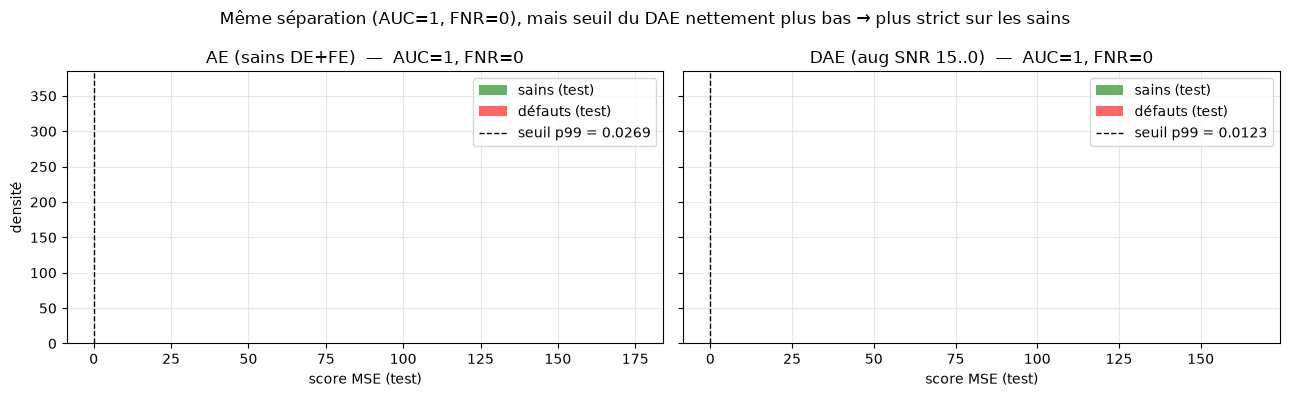

In [9]:
# === Illustration : seuil DAE plus bas, séparation identique ===
y_test = (infos["defaut_sain"].to_numpy()[i_test] == "Défaut")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, modele, tag in [(axes[0], modele_AE, "AE (sains DE+FE)"),
                        (axes[1], modele_DAE, "DAE (aug SNR 15..0)")]:
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)      # p99 du train sain
    s = score[i_test]
    ax.hist(s[~y_test], bins=60, density=True, alpha=0.6, color="green", label="sains (test)")
    ax.hist(s[y_test],  bins=60, density=True, alpha=0.6, color="red",   label="défauts (test)")
    ax.axvline(seuil, color="black", ls="--", lw=1, label=f"seuil p99 = {seuil:.4f}")
    ax.set_title(f"{tag}  —  AUC=1, FNR=0"); ax.set_xlabel("score MSE (test)")
    ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("densité")
fig.suptitle("Même séparation (AUC=1, FNR=0), mais seuil du DAE nettement plus bas → plus strict sur les sains")
plt.tight_layout(); plt.show()

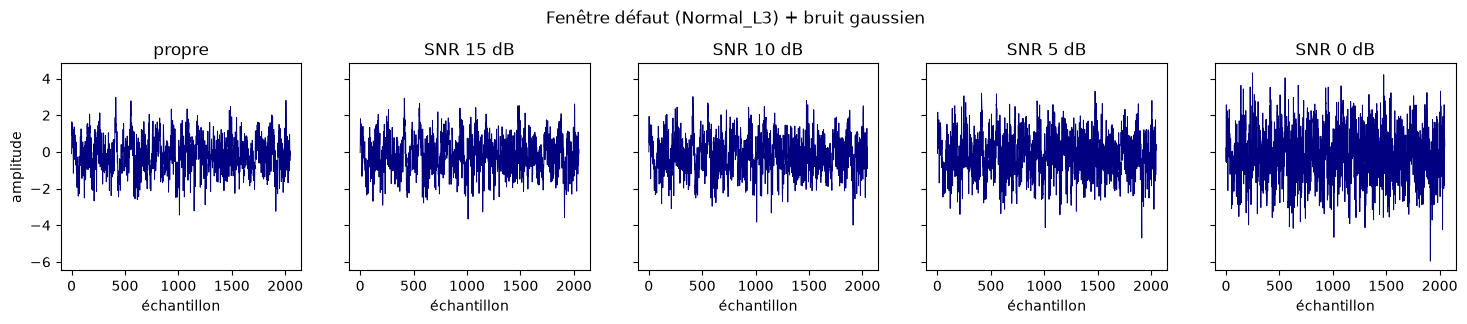

In [10]:
#| label: fig-bruit
#| fig-cap: "Même fenêtre défaut à différents SNR (bruit gaussien ajouté) : propre, 15, 10, 5, 0 dB."
# i_def = i_test[~sain[i_test]][520]                 # une fenêtre défaut du test
i_def = i_test[sain[i_test]][0]                 # une fenêtre défaut du test
x = SBNorm[i_def]

niveaux = [None, 15, 10, 5, 0]                    # None = signal propre
titres  = ["propre", "SNR 15 dB", "SNR 10 dB", "SNR 5 dB", "SNR 0 dB"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3), sharex=True, sharey=True)   # mêmes échelles
for ax, snr, titre in zip(axes, niveaux, titres):
    xb = x if snr is None else ajouter_bruit(x, snr, seed=42)   # même bruit reproductible
    ax.plot(xb, color="navy", lw=0.7)
    ax.set_title(titre); ax.set_xlabel("échantillon")
axes[0].set_ylabel("amplitude")
fig.suptitle(f"Fenêtre défaut ({infos.loc[i_def, 'fichier']}) + bruit gaussien")
plt.subplots_adjust(top=0.80)
plt.show()